In [2]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [85]:
import glob
from PlateDict import rev_wellMap, wellMap

In [7]:
orf_mapping = GetOrfMapping()
orf_to_symbol = dict(zip(orf_mapping.orf_id, orf_mapping.symbol))
orf_to_ensg =   dict(zip(orf_mapping.orf_id, orf_mapping.ensembl_gene_id))
symbol_to_ensg = dict(zip(orf_mapping.symbol, orf_mapping.ensembl_gene_id))

## Load VUS dataset

In [8]:
allele_infos_d = {}
allele_aa_cs_d = {}
ccsb_col = GetDFv2()
for orf_id, rc4_mut_id, cegs_mut_id, vus_mut_id, aa_change, clinical_significance in zip(ccsb_col.orf_id, ccsb_col.rc4_mut_id, ccsb_col.cegs_mut_id, ccsb_col.vus_mut_id, ccsb_col.aa_change, ccsb_col.clinical_significance):
    for mut_id in [rc4_mut_id,cegs_mut_id,vus_mut_id]:
        if mut_id == mut_id:
            allele_infos_d[(orf_id,mut_id)] = (aa_change,clinical_significance)
            allele_aa_cs_d[(orf_id,aa_change)] = clinical_significance
    allele_infos_d[(orf_id,0)] = ('WT','WT')
    allele_aa_cs_d[(orf_id,'WT')] = 'WT'



orf_mapping = GetOrfMapping()
orf_to_symbol = dict(zip(orf_mapping.orf_id, orf_mapping.symbol))
orf_to_ensg =   dict(zip(orf_mapping.orf_id, orf_mapping.ensembl_gene_id))
symbol_to_ensg = dict(zip(orf_mapping.symbol, orf_mapping.ensembl_gene_id))


q = 'select disease_orf_id, swim_seq_validated from vus.wt_disease_nodes_summary;'
col = ['disease_orf_id', 'swim_seq_validated']

wt_disease_nodes_summary = GetDFv2(q,col)
wt_validated_d = dict(zip(wt_disease_nodes_summary.disease_orf_id, wt_disease_nodes_summary.swim_seq_validated))

q = 'select ad_orf_id, assay_id, swim_seq_validated from vus.vus_ad_interactors;'
col = ['ad_orf_id', 'assay_id', 'swim_seq_validated']

vus_ad_interactors = GetDFv2(q,col)
vus_ad_interactors_d = dict(zip(vus_ad_interactors.ad_orf_id, vus_ad_interactors.swim_seq_validated))

q = 'select orf_id, mut_id, nt_change, swim_seq_validated from vus.vus_db_alleles;'
col = ['orf_id', 'mut_id', 'nt_change', 'swim_seq_validated']

vus_db_alleles = GetDFv2(q,col)
vus_db_alleles_d = {(o,m):s for o,m,s in zip(vus_db_alleles.orf_id, vus_db_alleles.mut_id, vus_db_alleles.swim_seq_validated)}


q = 'select ad_orf_id, db_orf_id, db_mut_id, retest_pla, retest_pos, standard_batch, assay_id, db_source_plate, db_source_well, ad_source_plate, ad_source_well, LW, LWH1, LWH10, LWH25, LWA, LWAH1, db_validated, ad_validated from vus.retest where standard_batch in ("VUSAPWT1B1","VUSAPWT1B2","VUSAPWT2B1","VUSAPWT6B1") and db_orf_id is not null and ad_orf_id is not null;'

col = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_pla', 'retest_pos', 'standard_batch', 'assay_id', 'db_source_plate', 'db_source_well', 'ad_source_plate', 'ad_source_well', 'LW', 'LWH1', 'LWH10', 'LWH25', 'LWA', 'LWAH1', 'db_validated', 'ad_validated']

retest_df = GetDFv2(q,col)

retest_df['db_source_validated'] = [vus_db_alleles_d[db,m] if (db,m) in vus_db_alleles_d else wt_validated_d[db] for db,m in zip(retest_df.db_orf_id, retest_df.db_mut_id)]
retest_df['ad_source_validated'] = retest_df.ad_orf_id.map(vus_ad_interactors_d)

retest_df['seq_validated'] = [(dbs == 1 or dbd == 1) and (ads == 1 or add == 1) for dbs, ads, dbd, add in zip(retest_df.db_source_validated, retest_df.ad_source_validated, retest_df.db_validated, retest_df.ad_validated)]


df = retest_df[(~retest_df.db_orf_id.isnull())&(retest_df.ad_orf_id == 0)&(retest_df.LW >= 1)&((retest_df.db_validated == 1)|(retest_df.db_source_validated==1))]

EAD_d = {(db_orf_id,db_mut_id):{'LWA':{}, 'LWH1':{}, 'LWH10':{}, 'LWH25':{}, 'LWAH1':{}} for db_orf_id,db_mut_id in  zip(df.db_orf_id, df.db_mut_id)}

for db_orf_id, db_mut_id, LW, LWA, LWH1, LWH10, LWH25, LWAH1 in zip(df.db_orf_id, df.db_mut_id, df.LW, df.LWA,df.LWH1,df.LWH10,df.LWH25,df.LWAH1):
    for media, score in zip(['LWA', 'LWH1', 'LWH10', 'LWH25', 'LWAH1'],[LWA, LWH1, LWH10, LWH25, LWAH1]):
        EAD_d[(db_orf_id,db_mut_id)][media] = score

def get_final_score(score, ead_score, LW_score):
    res = np.nan
    
    if score == score and ead_score == ead_score and LW_score == LW_score:
        if LW_score > 0:
            if score == 0:
                res = score
            elif ead_score == 0:
                res = score
            else:
                res = score - ead_score if score - ead_score >= 2 else np.nan
            
    return res 


col = ['ad_orf_id', 'db_orf_id', 'db_mut_id','standard_batch', 'assay_id', 'LW', 'LWH1', 'LWH10', 'LWH25','LWA', 'LWAH1']

edgotyping_df = retest_df[(retest_df.ad_orf_id > 0)&(retest_df.seq_validated)&(retest_df.LW > 0)][col].copy()

for media in ['LWH1', 'LWH10', 'LWH25', 'LWA', 'LWAH1']:
    edgotyping_df[f'ead_{media}'] = [EAD_d[(db_orf_id, db_mut_id)][media] if (db_orf_id, db_mut_id) in EAD_d else np.nan for db_orf_id, db_mut_id in zip(edgotyping_df.db_orf_id, edgotyping_df.db_mut_id)]
    edgotyping_df[f'{media}_f'] = [get_final_score(score, ead_score,LW_score) for score, ead_score, LW_score in zip(edgotyping_df[media], edgotyping_df[f'ead_{media}'], edgotyping_df.LW)]


edgotyping_df.drop(columns=['LWH1','LWH10','LWH25','LWA','LWAH1','ead_LWA','ead_LWH1','ead_LWH10','ead_LWH25','ead_LWAH1'], inplace=True)
edgotyping_df['n_condition'] = [sum([1 for e in [c1,c2,c3,c4,c5] if e == e]) for c1,c2,c3,c4,c5 in zip(edgotyping_df.LWH1_f, edgotyping_df.LWH10_f, edgotyping_df.LWH25_f, edgotyping_df.LWA_f, edgotyping_df.LWAH1_f)]
edgotyping_df['score'] = [sum([1 for e in [c1, c2, c3, c4, c5] if e >= 1]) for c1, c2, c3, c4, c5 in zip(edgotyping_df.LWH1_f, edgotyping_df.LWH10_f, edgotyping_df.LWH25_f, edgotyping_df.LWA_f, edgotyping_df.LWAH1_f )]
edgotyping_df['score_norm'] = edgotyping_df.score / edgotyping_df.n_condition
#edgotyping_df['score_norm_non_null'] = (edgotyping_df.score+1) / (edgotyping_df.n_condition+1)


df = edgotyping_df[(edgotyping_df.n_condition >= 3)&(edgotyping_df.db_mut_id == 0)]

wt_scored_d =  {(db,ad):s for db,ad,s in zip(df.db_orf_id, df.ad_orf_id, df.score_norm)}



allele_df = edgotyping_df[(edgotyping_df.db_mut_id < 999999)].copy()
allele_df['wt_score_norm'] = [wt_scored_d[db,ad] if (db,ad) in wt_scored_d else np.nan for db,ad in zip(allele_df.db_orf_id, allele_df.ad_orf_id)]
allele_df.rename(columns = {'score_norm':'allele_score_norm'}, inplace=True)
allele_df['valid'] = (allele_df.wt_score_norm>0)&(~allele_df.allele_score_norm.isnull())&(allele_df.n_condition > 2)

ccsb_coll = GetDFv2()
allele_mut_d = {}
for o,nt,aa,rc4,vus,cegs,cs in zip(ccsb_coll.orf_id, ccsb_coll.nt_change, ccsb_coll.aa_change, ccsb_coll.rc4_mut_id, ccsb_coll.vus_mut_id, ccsb_coll.cegs_mut_id, ccsb_coll.clinical_significance):
    for m in [rc4,vus,cegs]:
        if m == m:
            allele_mut_d[(o,m)] = (nt,aa,cs)
            
allele_df['db_symbol'] = allele_df.db_orf_id.map(orf_to_symbol)
allele_df['db_ensembl_gene_id'] = allele_df.db_orf_id.map(orf_to_ensg)
allele_df['ad_symbol'] = allele_df.ad_orf_id.map(orf_to_symbol)
allele_df['ad_ensembl_gene_id'] = allele_df.ad_orf_id.map(orf_to_ensg)

allele_df['nt_change'] = [allele_mut_d[o,m][0] if (o,m) in allele_mut_d else 'WT' for o,m in zip(allele_df.db_orf_id, allele_df.db_mut_id)]
allele_df['aa_change'] = [allele_mut_d[o,m][1] if (o,m) in allele_mut_d else 'WT' for o,m in zip(allele_df.db_orf_id, allele_df.db_mut_id)]
allele_df['clinical_significance'] = [allele_mut_d[o,m][2] if (o,m) in allele_mut_d else 'WT' for o,m in zip(allele_df.db_orf_id, allele_df.db_mut_id)]


allele_df.drop(columns=['standard_batch','assay_id','LW','LWH1_f','LWH10_f','LWH25_f','LWA_f','LWAH1_f','n_condition','score'],inplace=True)
allele_df.rename(columns={'allele_score_norm':'allele_score','wt_score_norm':'wt_score'},inplace=True)

col = ['ad_orf_id', 'ad_symbol','ad_ensembl_gene_id','db_orf_id', 'db_symbol', 'db_ensembl_gene_id','db_mut_id', 'nt_change', 'aa_change','clinical_significance', 'allele_score',
       'wt_score']

allele_df = allele_df[allele_df.valid == True][col].copy()
#allele_df.reset_index(drop=True).to_csv('Y2H_allele_edgotyping.csv', sep=',')

edg_d = dict()
#for i, (ad_orf_id,db_orf_id,db_mut_id,standard_batch,LWA_f,LWH1_f,LWH10_f,LWH25_f,LWAH1_f,db_symbol,ad_symbol,all_scores,sum_scores,n_media,norm_score,aa_change) in processed_df.iterrows():
for i,(ad_orf_id,ad_symbol,ad_ensembl_gene_id,db_orf_id,db_symbol,db_ensembl_gene_id,db_mut_id,nt_change,aa_change,clinical_significance,allele_score,wt_score) in allele_df.iterrows():
    #assay_id = int(standard_batch[-3])
    if (db_orf_id, aa_change) not in edg_d:
        edg_d[(db_orf_id, aa_change)] =  {'ad_profile':{ad_symbol:allele_score}}
    else:
        edg_d[(db_orf_id, aa_change)]['ad_profile'][ad_symbol] = allele_score
        
all_d = {orf_id:dict() for orf_id in allele_df.db_orf_id}
#for i, (ad_orf_id,db_orf_id,db_mut_id,standard_batch,LWA_f,LWH1_f,LWH10_f,LWH25_f,LWAH1_f,db_symbol,ad_symbol,all_scores,sum_scores,n_media,allele_score,aa_change) in processed_df.iterrows():
for i,(ad_orf_id,ad_symbol,ad_ensembl_gene_id,db_orf_id,db_symbol,db_ensembl_gene_id,db_mut_id,nt_change,aa_change,clinical_significance,allele_score,wt_score) in allele_df.iterrows():    
    #assay_id = int(standard_batch[-3])
    if aa_change not in all_d[db_orf_id]:
        all_d[db_orf_id][aa_change] =  {ad_symbol:allele_score}
    else:
        all_d[db_orf_id][aa_change][ad_symbol] = allele_score


        
edg_df = pd.DataFrame(edg_d).T
edg_df.reset_index(inplace=True)
edg_df.rename(columns={'level_0':'db_orf_id', 'level_1':'aa_change'},inplace=True)
edg_df['db_symbol'] = edg_df.db_orf_id.map(orf_to_symbol)
wt_d = dict(zip(edg_df[edg_df.aa_change == 'WT'].db_orf_id, edg_df[edg_df.aa_change == 'WT'].ad_profile))
#d = {(db_orf_id,aa_change):ad_orf_id for db_orf_id,aa_change, ad_orf_id in zip(edg_df.db_orf_id, edg_df.aa_change, edg_df.ad_orf_id)}
edg_df['wt_score'] = edg_df.db_orf_id.map(wt_d)
edg_df['clinical_significance'] = [allele_aa_cs_d[(db_orf_id,aa_change)] for db_orf_id, aa_change in zip(edg_df.db_orf_id, edg_df.aa_change)]
edg_df['n_allele'] = edg_df.db_orf_id.apply(lambda x: dict(edg_df.db_orf_id.value_counts())[x] - 1)
edg_df['degree_tested'] = edg_df.ad_profile.apply(len)
#edg_df['aa_change'] = [allele_infos_d[(orf,mut_id)][0] for orf, mut_id in zip(edg_df.db_orf_id, edg_df.aa_change)]
#edg_df['cs'] = [allele_infos_d[(orf,mut_id)][1] for orf, mut_id in zip(edg_df.db_orf_id, edg_df.aa_change)]
edg_df.sort_values(by=['db_orf_id','aa_change'],inplace=True)

def calculate_similarity(mut_profile1, mut_profile2):
    '''
    - return 1 if same as WT
    - less than 1 if 
    '''
    
    keys = {k for k in mut_profile1.keys()&mut_profile2.keys() if mut_profile1[k] == mut_profile1[k] and mut_profile2[k] == mut_profile2[k]}
    res = np.mean([1 - (abs(mut_profile1[k] - mut_profile2[k])/max([mut_profile1[k], mut_profile2[k]])) if mut_profile1[k] + mut_profile2[k] > 0 else 1 for k in keys])
    
    return res



def calculate_similarity_euclid_max_score_norm(mut_profile1, mut_profile2, wt_profile, how='euclid'):
    '''calculate similarity between two profiles
    
    return a score between 0 and 1
    distance can be calculated using euclidean 
    score = distance / max distance 
    how: euclid or taxicab (default is euclid)
    
    '''
    
    method = 2 if how == 'euclid' else 1
    
    keys = {k for k in mut_profile1.keys()&mut_profile2.keys() if mut_profile1[k] == mut_profile1[k] and mut_profile2[k] == mut_profile2[k]}
    #only keep interactions that have non null interaction score
    
    dist = sum(abs(mut_profile1[k] - mut_profile2[k])**method for k in keys)**(1/method) 
    max_dist = sum(max(mut_profile1[k], mut_profile2[k], wt_profile[k])**method for k in keys)**(1/method) 
    #max_dist = sum(max(wt_profile[k])**method for k in keys)**(1/method) 
    
    #print(dist, max_dist, 1-dist/max_dist)
    if len(keys) > 0:
        score = 1-(dist/max_dist)
    else:
        score = np.nan
    #except:
    #    print(mut_profile1)
    #    print(print(keys))
    #    print(mut_profile2)
    #    raise
    
    return score
    
# calculate_similarity_euclidean({'int_1':1,'int_2':1}, {'int_1':0,'int_2':1}, how='taxicab')
# calculate_similarity_euclidean({'int_1':1,'int_2':1}, {'int_1':.5,'int_2':.5}, how='taxicab')

# calculate_similarity_euclidean({'int_1':1,'int_2':1}, {'int_1':0,'int_2':1}, how='euclid')
# calculate_similarity_euclidean({'int_1':1,'int_2':1}, {'int_1':.5,'int_2':.5}, how='euclid')

edg_df['wt_similarity'] = [calculate_similarity_euclid_max_score_norm(allele_profile, wt_profile, wt_profile) for allele_profile, wt_profile in zip(edg_df.ad_profile, edg_df.wt_score)]
edg_df['similarity'] = [{aa_change:calculate_similarity_euclid_max_score_norm(allele_profile,all_d[db_orf_id][aa_change], wt_profile) for aa_change in  all_d[db_orf_id]} for allele_profile, db_orf_id, wt_profile in zip(edg_df.ad_profile, edg_df.db_orf_id, edg_df.wt_score)]

wt_similarity_d = {(orf_id, aa_change):similarity for orf_id, aa_change, similarity in zip(edg_df.db_orf_id, edg_df.aa_change, edg_df.wt_similarity)}

edg_df.head()

,db_orf_id,aa_change,ad_profile,db_symbol,wt_score,clinical_significance,n_allele,degree_tested,wt_similarity,similarity
555,138,WT,"{'RNF4': 0.4, 'SPOPL': 1.0, 'IRAK4': 1.0, 'MYD...",MYD88,"{'RNF4': 0.4, 'SPOPL': 1.0, 'IRAK4': 1.0, 'MYD...",WT,0,4,1.0,{'WT': 1.0}
747,143,Arg684Cys,{'EED': 0.6},EZH2,{'EED': 0.6},Pathogenic,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."
740,143,His694Tyr,{'EED': 0.6},EZH2,{'EED': 0.6},Pathogenic,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."
769,143,Pro132Ser,{'EED': 0.6},EZH2,{'EED': 0.6},Pathogenic,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."
898,143,WT,{'EED': 0.6},EZH2,{'EED': 0.6},WT,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."


## Load yN2H data

In [39]:
res = {}
for f in glob.glob('../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/*.xls'):
    a
    retest_pla = int(f.split('_')[6].split('Plate')[-1])
    if  retest_pla < 38:
        replicate = 1
    else:
        retest_pla -= 37
        replicate = 2
        
    df = pd.read_excel(f, skiprows=10, skipfooter=35,engine='xlrd')
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (retest_pla,replicate,f'{l}{str(i+1).zfill(2)}')
            res[key] = value

../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate68_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate39_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate33_yN2Hapwt_Rep1_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate71_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate69_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate38_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-

*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate56_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate50_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate12_yN2Hapwt_Rep1_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate49_yN2Hapwt_Rep2_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate13_yN2Hapwt_Rep1_P.xls
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
../../yN2H_experiment/20210331_yN2H_APWT/20210329_VUS_yN2Hapwt/20210329_Plate51_yN2Hapwt_Rep

In [40]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol', 'db_mut_id', 'retest_pla', 'retest_pos',
       'standard_batch', 'variant_id']

query = f'select distinct { ", ".join(c for c in col)} from vus.retest where `standard_batch` in ("yN2Hapwt");'

yN2H_retest = GetDFv2(query, col)
yN2H_retest['yN2H_score_rep1'] = [res[(pla, 1, pos)] for pla, pos in zip(yN2H_retest.retest_pla, yN2H_retest.retest_pos)]
yN2H_retest['yN2H_score_rep2'] = [res[(pla, 2, pos)] for pla, pos in zip(yN2H_retest.retest_pla, yN2H_retest.retest_pos)]

yN2H_retest.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2
0,71963,MBD3L1,2713,MLH1,981.0,4,H05,yN2Hapwt,allele,96,82
1,11452,WASHC1,4723,TPM1,201730.0,4,G05,yN2Hapwt,allele,336,103
2,361,GRAMD2B,3438,TMEM43,0.0,4,F05,yN2Hapwt,wt,6558,2033
3,71892,TH,71892,TH,4005.0,4,E05,yN2Hapwt,allele,1092,254
4,2500,ZNF212,2713,MLH1,0.0,4,D05,yN2Hapwt,wt,124,82


In [41]:
empty_well_df = pd.read_excel('../../yN2H_experiment/20210331_yN2H_APWT/20210328_yN2H_empty_wells.xlsx',sheet_name='Sheet2')
empty_well_df['replicate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[2][-1]))
empty_well_df['plate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[-1].replace('Plate','')))
empty_well_df['empty_wells'] = empty_well_df['Empty wells'].apply(lambda x: {f"{e.replace(' ','')[0]}{e.replace(' ','')[1:].zfill(2)}" for e in x.split(',')})
#empty_well_d = {(plate,rep):wells for plate, rep, wells in zip(empty_well_df.plate, empty_well_df.replicate, empty_well_df.empty_wells)}       
empty_well_set =  {(plate, rep, well) for plate, rep, wells in zip(empty_well_df.plate, empty_well_df.replicate, empty_well_df.empty_wells) for well in wells }

empty_well_df.head()

,Plates,Empty wells,replicate,plate,empty_wells
0,Plate1_yN2Hapwt_Rep1_Plate1,"E1, A9, B10, G12, H12",1,1,"{E01, A09, H12, B10, G12}"
1,Plate2_yN2Hapwt_Rep1_Plate2,"G7, F8, G12, H12",1,2,"{H12, F08, G07, G12}"
2,Plate3_yN2Hapwt_Rep1_Plate3,"B1, B10, G12, H12",1,3,"{B10, H12, G12, B01}"
3,Plate4_yN2Hapwt_Rep1_Plate4,"C1, A3, C4, B5, D8, G12, H12",1,4,"{D08, H12, B05, A03, C04, C01, G12}"
4,Plate5_yN2Hapwt_Rep1_Plate5,"B2, D5, A8, B8, E8, G8, B9, G12, H12",1,5,"{H12, G08, B08, A08, E08, B09, B02, D05, G12}"


In [42]:
query = '''select orf_id, mut_id from vus.N2H_validation_nodes where collection = "rc4" '''
col = ['db_orf_id','db_mut_id']
rc4_mut_ids = GetDFv2(query,col)
rc4_mut_ids = set(zip(rc4_mut_ids.db_orf_id, rc4_mut_ids.db_mut_id))

In [43]:
yN2H_retest['empty_well_rep1'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or (plate,1,retest_pos) in empty_well_set for db_orf_id, db_mut_id, plate, retest_pos in zip(yN2H_retest.db_orf_id, yN2H_retest.db_mut_id, yN2H_retest.retest_pla, yN2H_retest.retest_pos)]
yN2H_retest['empty_well_rep2'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or (plate,2,retest_pos) in empty_well_set for db_orf_id, db_mut_id, plate, retest_pos in zip(yN2H_retest.db_orf_id, yN2H_retest.db_mut_id, yN2H_retest.retest_pla, yN2H_retest.retest_pos)]

yN2H_retest.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2
0,71963,MBD3L1,2713,MLH1,981.0,4,H05,yN2Hapwt,allele,96,82,False,False
1,11452,WASHC1,4723,TPM1,201730.0,4,G05,yN2Hapwt,allele,336,103,False,False
2,361,GRAMD2B,3438,TMEM43,0.0,4,F05,yN2Hapwt,wt,6558,2033,False,False
3,71892,TH,71892,TH,4005.0,4,E05,yN2Hapwt,allele,1092,254,False,False
4,2500,ZNF212,2713,MLH1,0.0,4,D05,yN2Hapwt,wt,124,82,False,False


In [84]:
empty_N1_rep1_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_orf_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_mut_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].yN2H_score_rep1)}
empty_N2_rep1_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].ad_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].yN2H_score_rep1))

empty_N1_rep2_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_orf_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_mut_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].yN2H_score_rep2)}
empty_N2_rep2_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].ad_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].yN2H_score_rep2))
 

yN2H_normalized = yN2H_retest[yN2H_retest.variant_id.isin(['wt', 'allele', 'RRS','PRS'])].copy()
#yN2H_normalized['pair'] = [tuple(sorted([x,y])) for x, y in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
#yN2H_normalized['variant_idv2'] = yN2H_normalized.variant_id.apply(lambda x: x if x !=  'litbm' else 'wt')

yN2H_normalized['empty_N1_rep1'] = [empty_N1_rep1_d[(db_orf_id, db_mut_id)] if db_mut_id == db_mut_id else empty_N1_rep1_d[(db_orf_id, 999999)] for db_orf_id,db_mut_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id)]
yN2H_normalized['empty_N2_rep1'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep1_d)

yN2H_normalized['empty_N1_rep2'] = [empty_N1_rep2_d[(db_orf_id, db_mut_id)] if db_mut_id == db_mut_id else empty_N1_rep2_d[(db_orf_id, 999999)] for db_orf_id,db_mut_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id)]
yN2H_normalized['empty_N2_rep2'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep2_d)


yN2H_normalized['NLR1'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['NLR2'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

#yN2H_normalized['NLD1'] = [N1N2-N1F2-N2F1 for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
#yN2H_normalized['NLD2'] = [N1N2-N1F2-N2F1 for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['NLR1'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLR1, yN2H_normalized.empty_well_rep1)]
yN2H_normalized['NLR2'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLR2, yN2H_normalized.empty_well_rep2)]
#yN2H_normalized['NLD1'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLD1, yN2H_normalized.empty_well_rep1)]
#yN2H_normalized['NLD2'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLD2, yN2H_normalized.empty_well_rep2)]

#yN2H_normalized['detected_r1'] = yN2H_normalized.NLR1.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR1.max())
#yN2H_normalized['detected_r2'] = yN2H_normalized.NLR2.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR2.max())

#yN2H_normalized['detected_NLD1'] = yN2H_normalized.NLD1.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLD1.max())
#yN2H_normalized['detected_NLD2'] = yN2H_normalized.NLD2.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLD2.max())

yN2H_normalized['NLR'] = [np.log2(np.mean([v for v in [v1, v2] if v == v])) for v1, v2 in zip(yN2H_normalized.NLR1, yN2H_normalized.NLR2)]
rrs_mean_nlr = np.mean(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR)
rrs_std_nlr = np.std(yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR)
yN2H_normalized['zNLR'] = yN2H_normalized.NLR.apply(lambda x: (x - rrs_mean_nlr) / rrs_std_nlr)

#yN2H_normalized['NLD'] = [np.mean([v for v in [v1, v2] if v == v]) for v1, v2 in zip(yN2H_normalized.NLD1, yN2H_normalized.NLD2)]

#yN2H_normalized['NLR_log2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score, yN2H_normalized.empty_N1, yN2H_normalized.empty_N2)]
yN2H_normalized['pair'] = [tuple(sorted([ad,db])) for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]

yN2H_d = {(ad_symbol, db_symbol, db_mut_id):(NLR,zNLR) for ad_symbol, db_symbol, db_mut_id, NLR, zNLR in zip(yN2H_normalized.ad_symbol, yN2H_normalized.db_symbol, yN2H_normalized.db_mut_id, yN2H_normalized.NLR, yN2H_normalized.zNLR)}

yN2H_normalized.head()

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3474: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLR,zNLR,pair
0,71963,MBD3L1,2713,MLH1,981.0,4,H05,yN2Hapwt,allele,96,82,False,False,62,199,76,144,0.482412,0.569444,-0.927062,0.381923,"(2713, 71963)"
1,11452,WASHC1,4723,TPM1,201730.0,4,G05,yN2Hapwt,allele,336,103,False,False,117,137,124,110,2.452555,0.830645,0.715103,1.383381,"(4723, 11452)"
2,361,GRAMD2B,3438,TMEM43,0.0,4,F05,yN2Hapwt,wt,6558,2033,False,False,144,1174,220,1264,5.586031,1.608386,1.846878,2.073582,"(361, 3438)"
3,71892,TH,71892,TH,4005.0,4,E05,yN2Hapwt,allele,1092,254,False,False,227,144,302,213,4.810573,0.841060,1.498668,1.861230,"(71892, 71892)"
4,2500,ZNF212,2713,MLH1,0.0,4,D05,yN2Hapwt,wt,124,82,False,False,165,185,199,117,0.670270,0.412060,-0.885859,0.407051,"(2500, 2713)"


In [83]:
yN2H_normalized[yN2H_normalized.zNLR > 2.23].variant_id.value_counts()

allele    255
wt         68
PRS        12
Name: variant_id, dtype: int64

In [81]:
yN2H_normalized.variant_id.value_counts()

allele    1786
wt         239
RRS         78
PRS         60
Name: variant_id, dtype: int64

In [50]:
df = yN2H_normalized[((yN2H_normalized.variant_id == 'wt'))&((yN2H_normalized.detected_r1)|(yN2H_normalized.detected_r2))]


yN2H_wt_detected_pairs = list(zip(df.db_symbol, df.ad_symbol))

## Load mN2H data

In [52]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol', 'db_mut_id','variant_id', 'retest_pla', 'retest_pos', 
       'standard_batch', 'N2H_raw_r01', 'N2H_raw_r02']

q = f'select {", ".join(c for c in col)} from vus.retest where standard_batch = ("mN2Hapwtv2")'
retest_df = GetDFv2(q, col)
retest_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in retest_df.columns},inplace=True)

retest_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,N2H_raw_r01,N2H_raw_r02
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,2.289505e+06,3.670188e+06
1,0,None,5001,NCK1,0,empty_N1,1,B01,mN2Hapwtv2,1.332813e+05,2.079707e+05
2,1108,LCP2,0,None,0,empty_N2,1,C01,mN2Hapwtv2,7.215733e+04,1.060023e+05
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,4.561767e+04,7.038533e+04
4,0,None,4447,STAC3,0,empty_N1,1,E01,mN2Hapwtv2,1.138400e+04,1.692433e+04


In [75]:
empty_N1_xp1_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].N2H_raw_r01))
empty_N2_xp1_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].N2H_raw_r01))

empty_N1_xp2_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].N2H_raw_r02))
empty_N2_xp2_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].N2H_raw_r02))

normalized_df = retest_df[retest_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_df['empty_N1_xp1'] = normalized_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp1'] = normalized_df.N1_orf_id.map(empty_N2_xp1_d)

normalized_df['empty_N1_xp2'] = normalized_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp2'] = normalized_df.N1_orf_id.map(empty_N2_xp2_d)

# normalized_df['max_EC1'] = [max(en1,en2) for en1, en2 in zip(normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
# normalized_df['max_EC2'] = [max(en1,en2) for en1, en2 in zip(normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

normalized_df['NLR_xp1'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_df.N2H_raw_r01, normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['NLR_xp2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_df.N2H_raw_r02, normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

df = normalized_df[normalized_df.variant_id == 'RRS']
normalized_df['zNLR1'] = normalized_df.NLR_xp1.apply(lambda x: (x-np.mean(df.NLR_xp1))/np.std(df.NLR_xp1))
normalized_df['zNLR2'] = normalized_df.NLR_xp2.apply(lambda x: (x-np.mean(df.NLR_xp2))/np.std(df.NLR_xp2))

normalized_df['NLR'] = normalized_df.apply(lambda x: np.mean([x.NLR_xp1, x.NLR_xp2]), axis=1)
normalized_df['zNLR'] = normalized_df.apply(lambda x: np.mean([x.zNLR1, x.zNLR2]), axis=1)

#qY2H_d
normalized_df['qY2H_score'] = [qY2H_d[n2,n2_mut,n1] if (n2,n2_mut,n1) in qY2H_d else np.nan for n2,n2_mut,n1 in zip(normalized_df.N2_orf_id, normalized_df.N2_mut_id, normalized_df.N1_orf_id)]
#normalized_df['yN2H_NLR'] = [yN2H_d[n1,n2,0][3] if (n1,n2,0) in yN2H_d else np.nan  for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]

mN2H_d = {(N1_symbol,N2_symbol,N2_mut_id):(np.mean([N2H_raw_r01,N2H_raw_r02]),np.mean([empty_N1_xp1,empty_N1_xp2]),np.mean([empty_N2_xp1,empty_N2_xp2]),NLR,zNLR) for N1_symbol,N2_symbol,N2_mut_id,NLR,zNLR,N2H_raw_r01,N2H_raw_r02,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2 in zip(normalized_df.N1_symbol, normalized_df.N2_symbol, normalized_df.N2_mut_id, normalized_df.NLR, normalized_df.zNLR, normalized_df.N2H_raw_r01, normalized_df.N2H_raw_r02, normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1, normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)}

normalized_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,N2H_raw_r01,N2H_raw_r02,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,zNLR,qY2H_score
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,2.289505e+06,3.670188e+06,133281.333333,60561.000000,2.079707e+05,91601.333333,4.102489,4.141402,1.153835,1.187649,4.121945,1.170742,NaN
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,4.561767e+04,7.038533e+04,11384.000000,1559.666667,1.692433e+04,2437.666667,2.002585,2.056176,0.265261,0.311324,2.029380,0.288293,NaN
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,mN2Hapwtv2,1.125092e+06,1.508690e+06,59592.666667,65487.333333,1.110043e+05,89346.000000,4.102683,3.764609,1.153917,1.029300,3.933646,1.091609,NaN
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,mN2Hapwtv2,3.247837e+05,6.428973e+05,840605.666667,445242.333333,1.126690e+06,928918.000000,-1.371950,-0.809430,-1.162673,-0.892959,-1.090690,-1.027816,NaN
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,mN2Hapwtv2,5.132370e+05,8.464307e+05,27121.333333,64519.000000,5.824200e+04,77501.666667,2.991829,3.449093,0.683860,0.896703,3.220461,0.790281,NaN


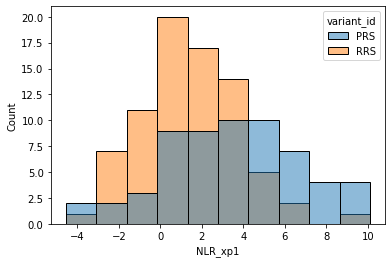

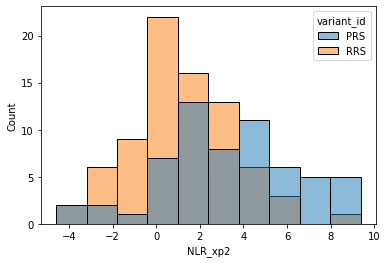

In [66]:
sns.histplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])],x='NLR_xp1',hue='variant_id');
plt.show()
sns.histplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])],x='NLR_xp2',hue='variant_id');
plt.show()

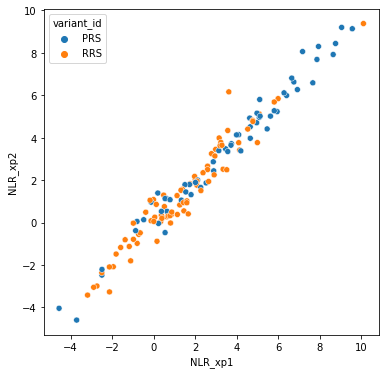

In [70]:
plt.figure(figsize=(6,6))

sns.scatterplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])], x='NLR_xp1', y='NLR_xp2', hue='variant_id');

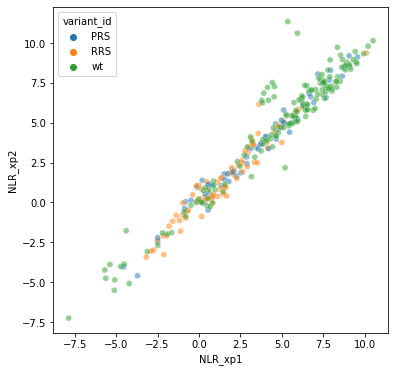

In [72]:
plt.figure(figsize=(6,6))

sns.scatterplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS','wt'])], x='NLR_xp1', y='NLR_xp2', hue='variant_id',alpha=0.5);

## Load LitBM

In [94]:
q = 'select distinct ensembl_gene_id, symbol from horfeome_annotation_gencode27.gencode2entrez'
ens_df = GetDFv2(q)
ens_df['ensembl_gene_id'] = ens_df.ensembl_gene_id.apply(lambda x: x.split('.')[0])
ens_to_symbol = dict(zip(ens_df.ensembl_gene_id, ens_df.symbol))
ens_df.head()

,ensembl_gene_id,ensembl_gene_id_short,symbol,entrez_gene_id,entrez_symbol
0,ENSG00000137692,NaN,DCUN1D5,NaN,NaN
1,ENSG00000220918,NaN,AL132875.1,NaN,NaN
2,ENSG00000134759,NaN,ELP2,NaN,NaN
3,ENSG00000008226,NaN,DLEC1,NaN,NaN
4,ENSG00000040633,NaN,PHF23,NaN,NaN


In [96]:
q = 'select * from hi2018_paper.lit_17 where category = "Lit-BM"'
litbm = GetDFv2(q)
litbm['symbol_a'] = litbm.ensembl_gene_id_a.map(ens_to_symbol)
litbm['symbol_b'] = litbm.ensembl_gene_id_b.map(ens_to_symbol)
litbm_s = set()
for symbol_a, symbol_b in zip(litbm.symbol_a, litbm.symbol_b):
    litbm_s.add((symbol_a, symbol_b))
    litbm_s.add((symbol_b, symbol_a))
litbm.head()

,ensembl_gene_id_a,ensembl_gene_id_b,binary_low_throughput,binary_not_y2h,binary_method,n_publications,n_methods,n_evidences,category,symbol_a,symbol_b
0,ENSG00000108469,ENSG00000181222,1,1,1,3,4,5,Lit-BM,RECQL5,POLR2A
1,ENSG00000078747,ENSG00000205726,1,1,1,1,2,2,Lit-BM,ITCH,ITSN1
2,ENSG00000161011,ENSG00000188554,1,0,1,9,5,9,Lit-BM,SQSTM1,NBR1
3,ENSG00000078747,ENSG00000123405,1,1,1,2,4,4,Lit-BM,ITCH,NFE2
4,ENSG00000173391,ENSG00000173391,1,1,1,2,4,4,Lit-BM,OLR1,OLR1


## Load stability

## Analysis

In [56]:
edg_df.head()

,db_orf_id,aa_change,ad_profile,db_symbol,wt_score,clinical_significance,n_allele,degree_tested,wt_similarity,similarity
555,138,WT,"{'RNF4': 0.4, 'SPOPL': 1.0, 'IRAK4': 1.0, 'MYD...",MYD88,"{'RNF4': 0.4, 'SPOPL': 1.0, 'IRAK4': 1.0, 'MYD...",WT,0,4,1.0,{'WT': 1.0}
747,143,Arg684Cys,{'EED': 0.6},EZH2,{'EED': 0.6},Pathogenic,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."
740,143,His694Tyr,{'EED': 0.6},EZH2,{'EED': 0.6},Pathogenic,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."
769,143,Pro132Ser,{'EED': 0.6},EZH2,{'EED': 0.6},Pathogenic,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."
898,143,WT,{'EED': 0.6},EZH2,{'EED': 0.6},WT,3,1,1.0,"{'His694Tyr': 1.0, 'Arg684Cys': 1.0, 'Pro132Se..."


### 120 disease genes

In [13]:
edgotyped_orf_ids = set(edg_df[edg_df.aa_change != 'WT'].db_orf_id)

In [11]:
edg_df[edg_df.aa_change != 'WT'].db_orf_id.nunique()

122

In [100]:
len(edg_df[edg_df.db_orf_id.isin(edgotyped_orf_ids)&(edg_df.aa_change != 'WT')])

784

In [99]:
wt_df = edg_df[(edg_df.db_orf_id.isin(edgotyped_orf_ids))&(edg_df.aa_change == 'WT')][['db_symbol','db_orf_id','ad_profile','n_allele','degree_tested']].copy()

attribute_s = set()
with open('labmeeting/network_120_genes.csv', 'w') as f, open('labmeeting/attributes_120_genes.csv','w') as f2:
    print('gene_a','gene_b','ppi_score', 'ppi_type', file=f, sep=',')
    for i, (db_symbol,db_orf_id,ad_profile,n_allele,degree_tested) in wt_df.iterrows():
        for ad_symbol,qY2H_score in ad_profile.items():
            if (ad_symbol, db_symbol) in litbm_s:
                print(db_symbol, ad_symbol, 1, 'litbm', file=f, sep=',')
            if (ad_symbol,db_symbol,0) in mN2H_d: #mN2H_d = {(N1_symbol,N2_symbol,N2_mut_id):(N2H_raw,empty_N1,empty_N2,NLR,zNLR)
                zNLR = mN2H_d[(ad_symbol,db_symbol,0)][-1]
                if zNLR >= 2.3:
                    wt_mN2H = 1
                    print(db_symbol, ad_symbol, wt_mN2H, 'mN2H', file=f, sep=',')
                #else:
                #    wt_mN2H = 0
                
            #else:
            #    wt_mN2H = 0
                
            if (ad_symbol,db_symbol,0) in yN2H_d: #yN2H_d = {(ad_symbol, db_symbol, db_mut_id):(NLR,zNLR) 
                zNLR = yN2H_d[(ad_symbol,db_symbol,0)][-1]
                if zNLR >= 2.3:
                    wt_yN2H = 1
                    print(db_symbol, ad_symbol, wt_yN2H, 'yN2H', file=f, sep=',')
                #else:
                #    wt_yN2H = 0
                    
            #else:
            #    wt_yN2H = 0         
                
            #print(db_symbol, ad_symbol, qY2H_score, wt_mN2H, wt_yN2H,file=f, sep='\t')
            print(db_symbol, ad_symbol, qY2H_score, 'qY2H', file=f, sep=',')

            attribute_s.add((db_symbol,1))
            if (ad_symbol,1) not in attribute_s:
                attribute_s.add((ad_symbol,0))
    print('gene_symbol','is_disease_gene', file=f2, sep=',')
    for s,dg in attribute_s:
        print(s,dg,sep=',',file=f2)
                
wt_df.head()



,db_symbol,db_orf_id,ad_profile,n_allele,degree_tested
898,EZH2,143,{'EED': 0.6},3,1
880,PTS,145,{'PTS': 0.75},4,1
5,MVK,281,{'MVK': 0.2},32,1
992,VPS33B,329,{'VIPAS39': 0.6},1,1
934,STAR,386,"{'AGTRAP': 0.4, 'RABEP1': 0.6, 'MAGEA11': 0.8}",4,3


In [29]:
len(attribute_s)

635

In [3]:
query = '''
SELECT 
   seq.id,
   seq.node_type,
	seq.plate,
	seq.well,
	seq.orf_id,
	seq.category,
	seq.orf_id_corrected,
	seq.coverage,
	node.mut_id,
	mut.nt_change

FROM
   tf_validation.plasmid_seq_group seq 
LEFT JOIN vus.N2H_validation_nodes node
   ON seq.plate = node.N2H_GDEh_plate AND 
      seq.well = node.N2H_GDEh_well

LEFT JOIN vus.vus_db_alleles mut
	on node.mut_id = mut.mut_id and
	   node.`orf_id` = mut.orf_id

WHERE node.node_type = "allele"; '''

col = ['id','node_type','plate','well','orf_id','category','orf_id_corrected','coverage','mut_id','nt_change']

allele_seq_df = GetDFv2(query,col)
allele_nt_change_to_mut_id = {(o,nt):(mut_id) for o,nt,mut_id in zip(allele_seq_df.orf_id, allele_seq_df.nt_change,allele_seq_df.mut_id)}
allele_seq_df.head()

,id,node_type,plate,well,orf_id,category,orf_id_corrected,coverage,mut_id,nt_change
0,7041,allele,VUSN2Hmut_GDEh_3,H10,100016069,VUS_MUT,100016069,0.955504,2653,976T>A
1,7040,allele,VUSN2Hmut_GDEh_3,H09,100016069,VUS_MUT,100016069,0.955504,2641,899G>A
2,7039,allele,VUSN2Hmut_GDEh_3,H08,100016069,VUS_MUT,100016069,0.955504,2627,566G>T
3,7038,allele,VUSN2Hmut_GDEh_3,H07,100016069,VUS_MUT,100016069,0.955504,2617,256G>T
4,7037,allele,VUSN2Hmut_GDEh_3,H06,100016069,VUS_MUT,100016069,0.955504,2607,208G>T


In [4]:
pps_wt_df = GetDFv2('select * from pooled_plasmid_seq.sample_align_call_full_wt')

pps_wt_df.head()

,pool_id,name,name_correct,orf_id,length,length_covered,avg_read,nt_change,expected,well
0,1,A05,None,1485,969,968,585.4700,23C>T,None,None
1,1,A06,None,5933,1200,1199,510.9666,1190C>G,None,None
2,1,A07,None,25,1074,789,86.3853,456T>C,None,None
3,1,B05,None,6806,2214,2213,390.8906,1558A>G,None,None
4,1,B05,None,14396,993,992,564.2238,676A>G,None,None


In [5]:
pps_allele_df = GetDFv2('select * from pooled_plasmid_seq.sample_align_call_full')
pps_allele_df['mut_id'] = [allele_nt_change_to_mut_id[o,nt] if (o,nt) in allele_nt_change_to_mut_id else np.nan for o,nt in zip(pps_allele_df.orf_id, pps_allele_df.nt_change)]

d = {(o,w):mut_id for o,w,mut_id in zip(pps_allele_df[~pps_allele_df.mut_id.isnull()].orf_id,
                                        pps_allele_df[~pps_allele_df.mut_id.isnull()].name,
                                        pps_allele_df[~pps_allele_df.mut_id.isnull()].mut_id
                                       )}
print(len(pps_allele_df))
print((pps_allele_df.mut_id.isnull()).sum())
pps_allele_df['mut_id'] = [d[o,w] if (o,w) in d else np.nan for o,w in zip(pps_allele_df.orf_id, pps_allele_df.name)]
print((pps_allele_df.mut_id.isnull()).sum())
pps_allele_df.head()

1180
448
376


,pool_id,name,name_correct,orf_id,length,length_covered,avg_read,nt_change,expected,well,mut_id
0,1,A01,None,2713,2268,2267,56.2889,1455T>A,1.0,None,200868.0
1,1,A01,None,3689,1395,1394,29.2181,532G>C,1.0,None,214822.0
2,1,A01,None,7323,480,479,49.8643,110A>T,1.0,None,216369.0
3,1,A01,None,11805,1275,1273,29.3284,657G>C,1.0,None,2137.0
4,1,A01,None,12573,1410,1409,30.4464,1013T>G,1.0,None,2295.0
